# 01 — Dataset quality & exploratory data analysis (METR-LA)

**Project 4 · Team T082 · Section B** — *Multi-Agent Traffic Flow Control via Graph Attention Networks and LWR Models*, Phase 1.

This notebook audits the METR-LA dataset and explores the temporal and spatial structure that the forecasting
models must exploit. Figures are produced by `scripts/run_eda.py` (run it first); the tables below are recomputed live.

**Dataset.** 207 loop detectors on Los Angeles highways, average speed (mph) every 5 minutes, 1 Mar – 27 Jun 2012
(34 272 timestamps), plus a directed road-distance sensor graph. Released with DCRNN (Li et al., ICLR 2018).

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
from trafficml import config as C, data, features as F, models as M, evaluate as E
pd.set_option("display.width", 140); pd.set_option("display.precision", 3)
def fig(name, width=820):
    display(Image(filename=str(C.FIGURES_DIR / f"{name}.png"), width=width))
print("project root:", ROOT)

project root: /home/claude/traffic-flow-phase1


## 1. Load the data
`load_all()` returns the speed table with outages masked as NaN, the raw table, and the sensor graph.

In [2]:
speed, raw, graph = data.load_all()
print("speed table:", speed.shape, "| from", speed.index[0], "to", speed.index[-1])
print("sampling interval:", pd.infer_freq(speed.index[:50]))
print("sensor graph: %d sensors, %d directed edges" % (graph.n, (graph.adjacency > 0).sum() - graph.n))
speed.iloc[:5, :6]

speed table: (34272, 207) | from 2012-03-01 00:00:00 to 2012-06-27 23:55:00
sampling interval: 5min
sensor graph: 207 sensors, 1515 directed edges


,773869,767541,767542,717447,717446,717445
timestamp,,,,,,
2012-03-01 00:00:00,64.375,67.625,67.125,61.500,66.875,68.750
2012-03-01 00:05:00,62.667,68.556,65.444,62.444,64.444,68.111
2012-03-01 00:10:00,64.000,63.750,60.000,59.000,66.500,66.250
2012-03-01 00:15:00,NaN,NaN,NaN,NaN,NaN,NaN
2012-03-01 00:20:00,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Data-quality audit

A reading of exactly **0 mph is a sensor outage**, not a traffic jam (a highway never averages 0 mph for a full 5-minute
window). We mask these values and never use them as features or targets. Below: how much is missing, and how the
outages are distributed over sensors and time.

In [3]:
summary = json.load(open(C.RESULTS_DIR / "eda_summary.json"))
keys = ["frac_zero_readings", "frac_timestamps_fully_missing", "sensors_missing_gt_20pct", "worst_sensor_missing",
        "outage_runs", "outage_run_median_steps", "outage_run_p90_steps", "outage_run_max_steps", "frac_outage_steps_in_runs_ge_1day",
        "n_missing_timestamps_in_index"]
pd.Series({k: summary[k] for k in keys}, name="value").to_frame()

,value
frac_zero_readings,0.081
frac_timestamps_fully_missing,0.063
sensors_missing_gt_20pct,1.000
worst_sensor_missing,0.201
outage_runs,25963.000
outage_run_median_steps,2.000
outage_run_p90_steps,71.000
outage_run_max_steps,1683.000
frac_outage_steps_in_runs_ge_1day,0.225
n_missing_timestamps_in_index,0.000


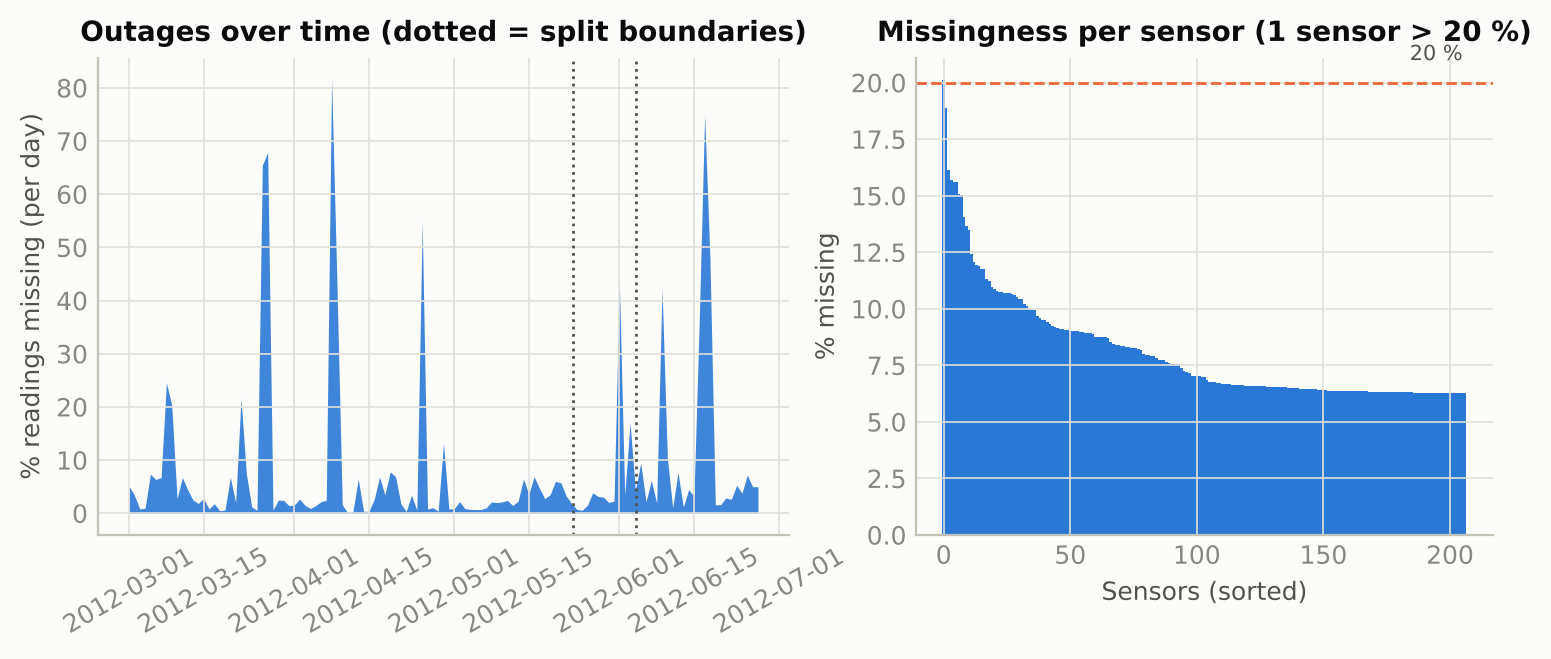

In [4]:
fig("fig_eda_missing")

**Reading the figure.** Outages are bursty: most runs are a few steps long, but a handful of day-long,
network-wide outages (spikes on the left) carry a quarter of all missing values. They occur in every split, so masking
(rather than dropping days) is the right treatment, and the models must cope with missing lags.

## 3. Speed distribution
The distribution is **bimodal** — a free-flow mode near 65 mph and a congested mode below 35 mph — the two regimes of the fundamental diagram.

In [5]:
obs = speed.values[~np.isnan(speed.values)]
pd.Series(obs).describe(percentiles=[.05, .25, .5, .75, .95]).to_frame("observed speed (mph)").T

,count,mean,std,min,5%,25%,50%,75%,95%,max
observed speed (mph),6.519e+06,58.46,13.024,0.333,25.625,57.125,63.222,66.5,68.889,70.0


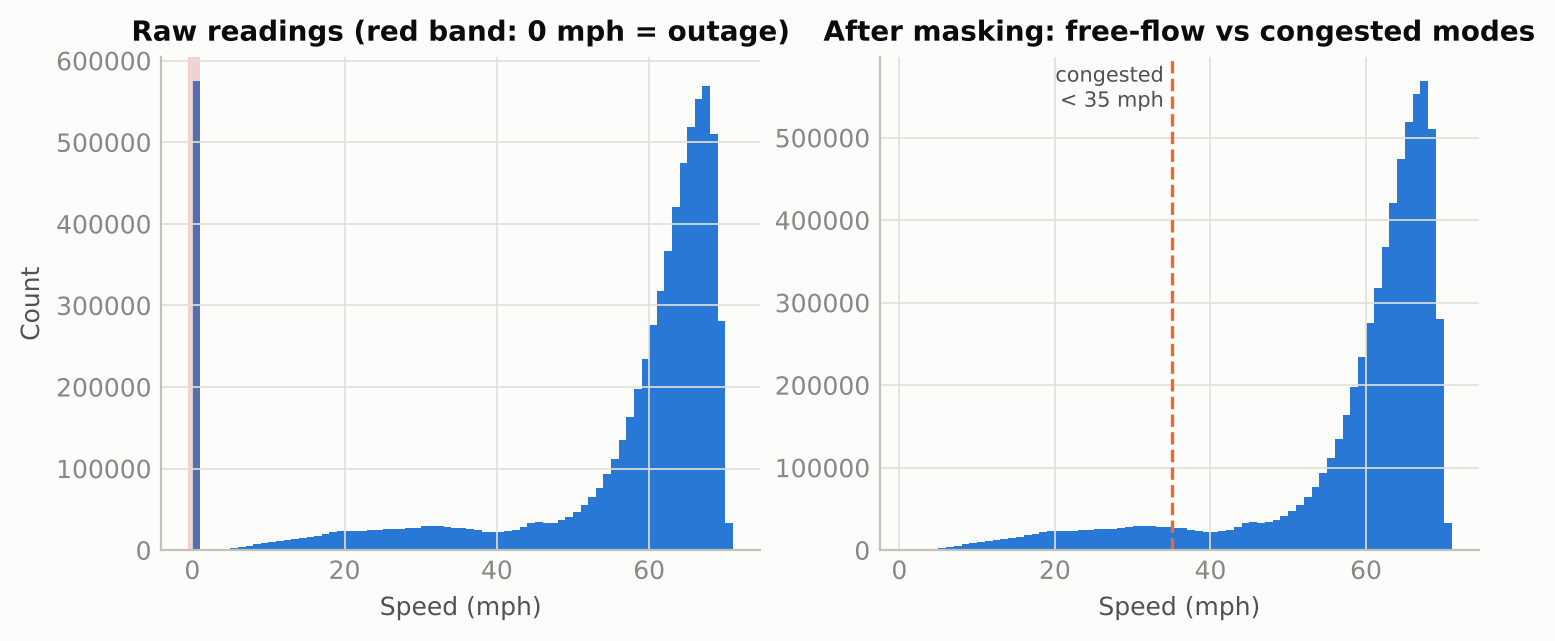

In [6]:
fig("fig_eda_speed_distribution")

## 4. Temporal structure
Two weekday commute peaks (evening deeper than morning), flat weekends, a strong one-hour memory and a 24-hour cycle.

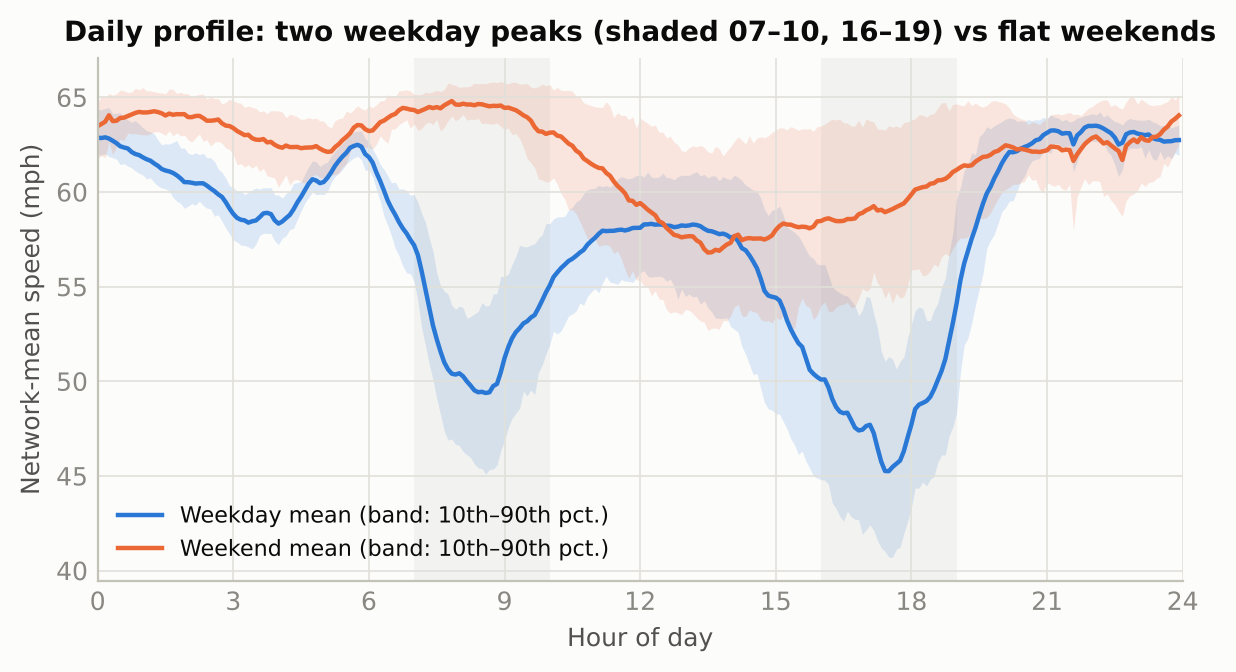

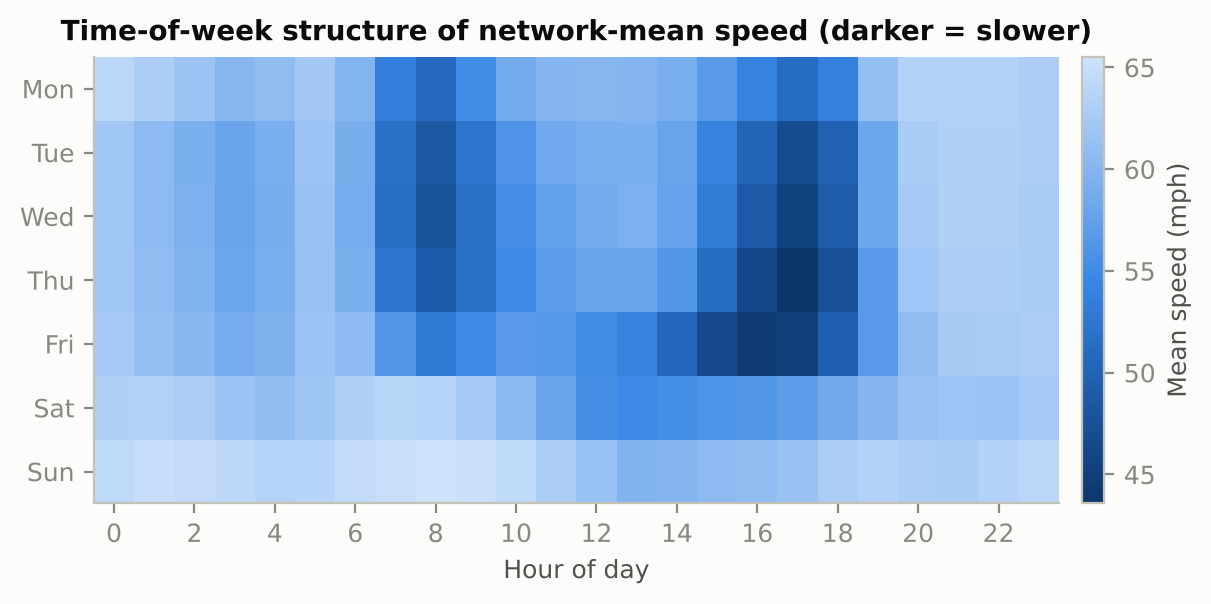

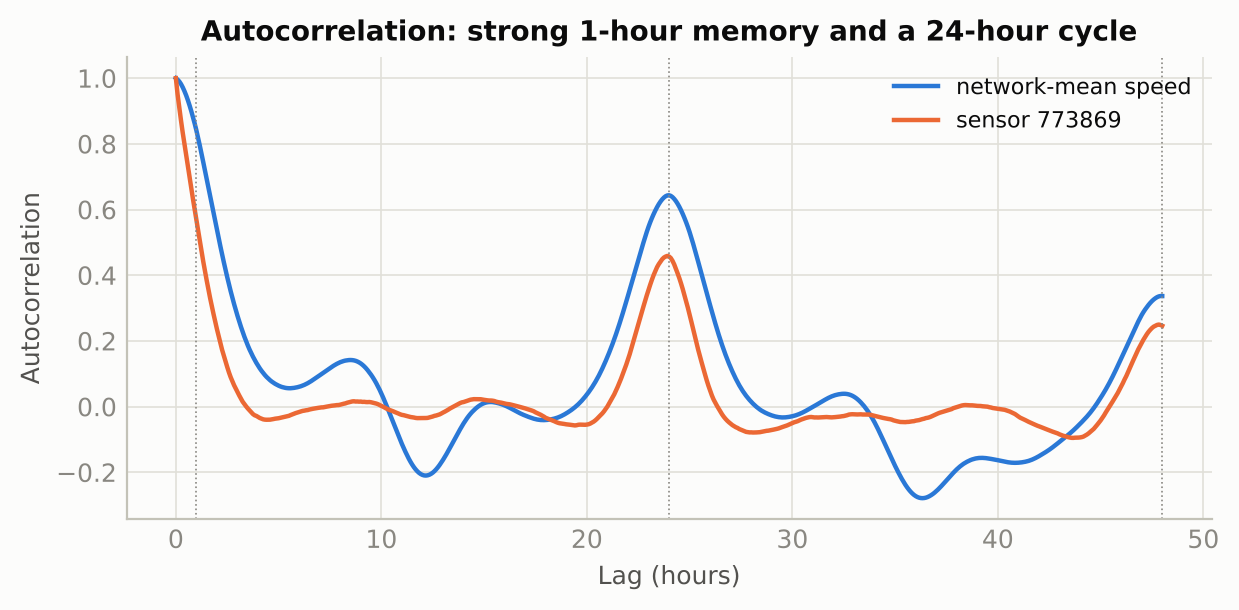

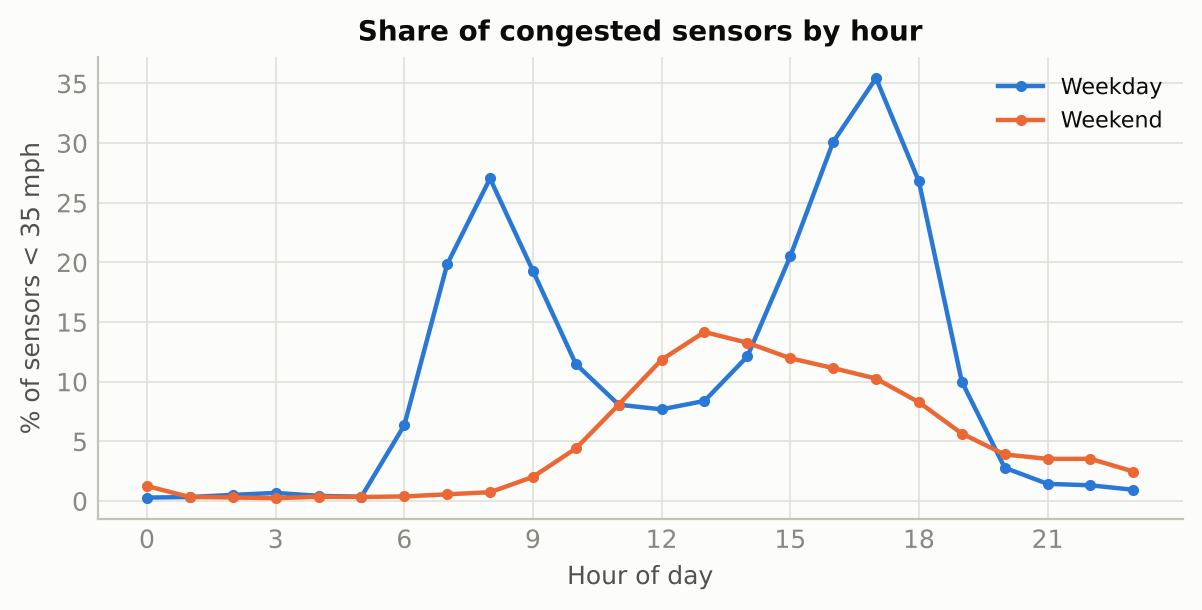

In [7]:
fig("fig_eda_daily_profile"); fig("fig_eda_weekly_heatmap"); fig("fig_eda_autocorrelation"); fig("fig_eda_congestion_by_hour")

In [8]:
# share of congested sensors by hour (weekdays)
X = speed.values; idx = speed.index
cong = np.where(np.isnan(X), np.nan, (X < C.CONGESTION_THRESHOLD).astype(float))
share = pd.DataFrame({"hour": idx.hour, "weekday": idx.dayofweek < 5, "congested": np.nanmean(cong, axis=1)})
(share.groupby(["weekday", "hour"]).congested.mean().unstack(0) * 100).round(1).T

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
weekday,,,,,,,,,,,,,,,,,,,,,
False,1.3,0.3,0.3,0.2,0.4,0.3,0.4,0.6,0.7,2.0,...,13.3,12.0,11.1,10.3,8.3,5.7,3.9,3.5,3.5,2.5
True,0.3,0.3,0.5,0.7,0.4,0.4,6.4,19.8,27.0,19.3,...,12.1,20.5,30.1,35.4,26.8,10.0,2.8,1.4,1.3,0.9


## 5. Spatial structure
Correlation between sensors decays with **road-network distance** — strong but local dependence, which motivates neighbour features now and a graph neural network in Phase 2.

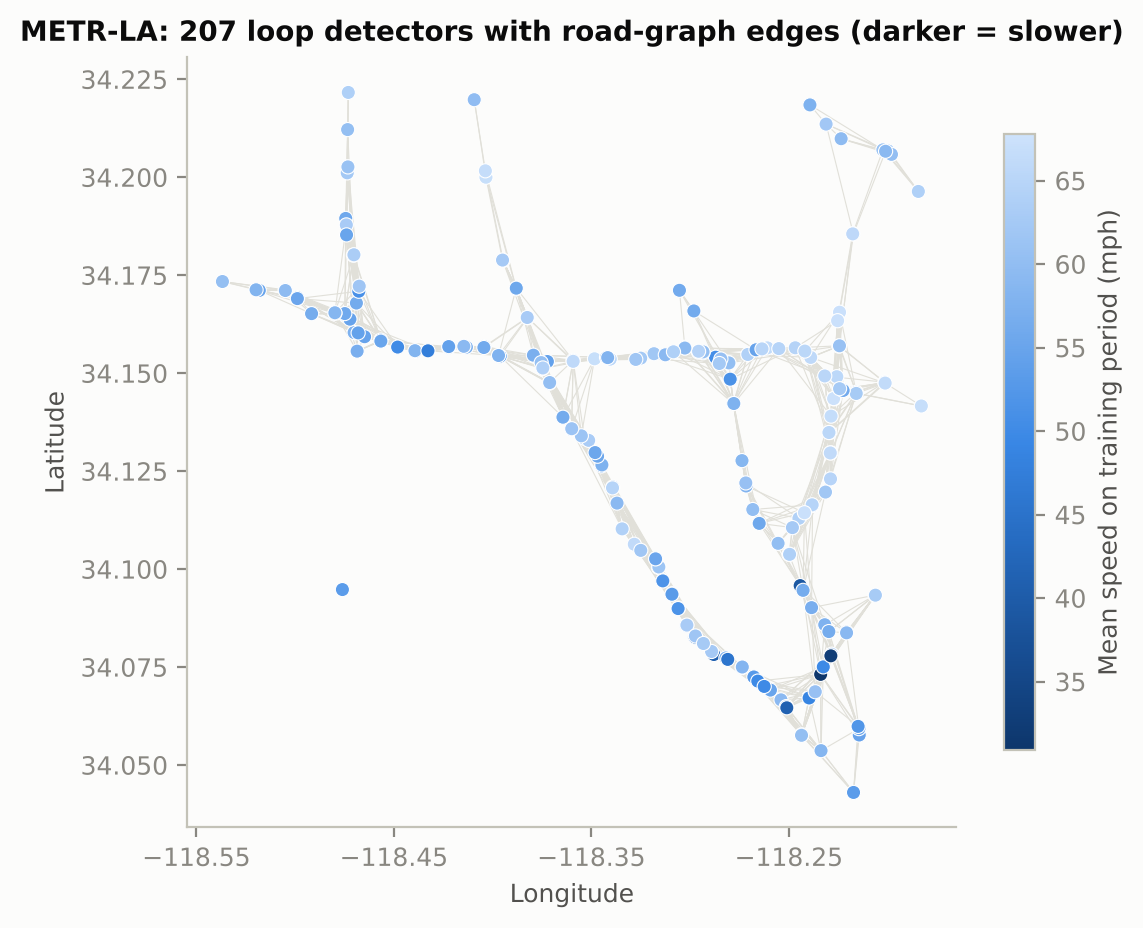

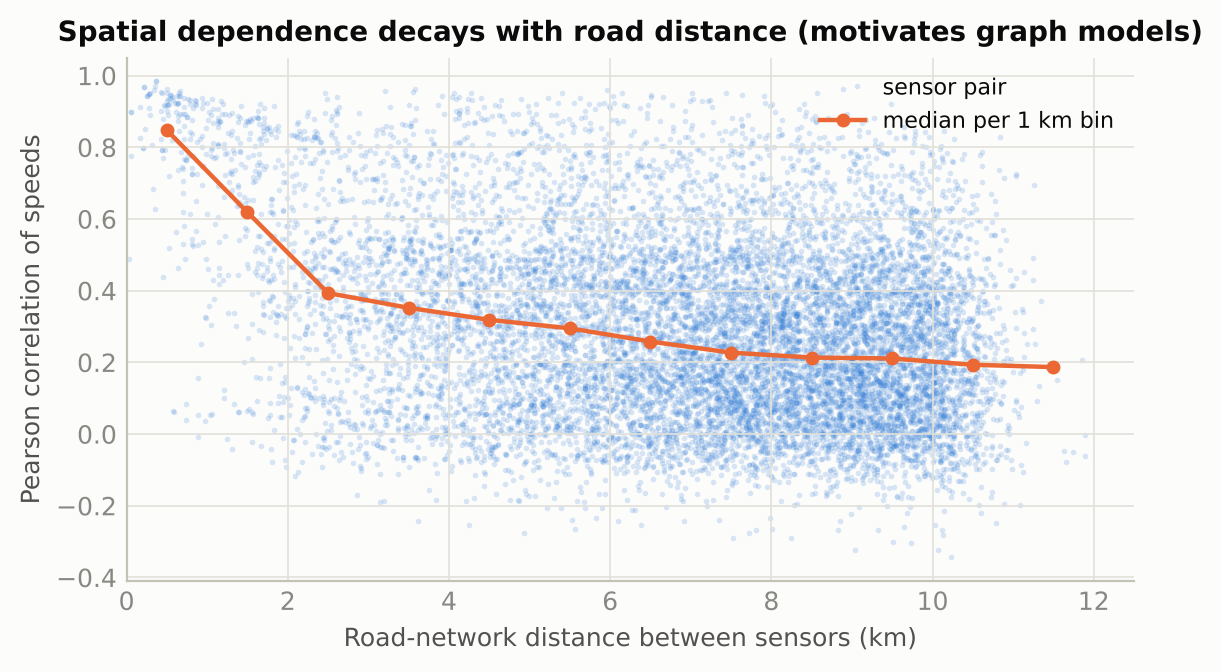

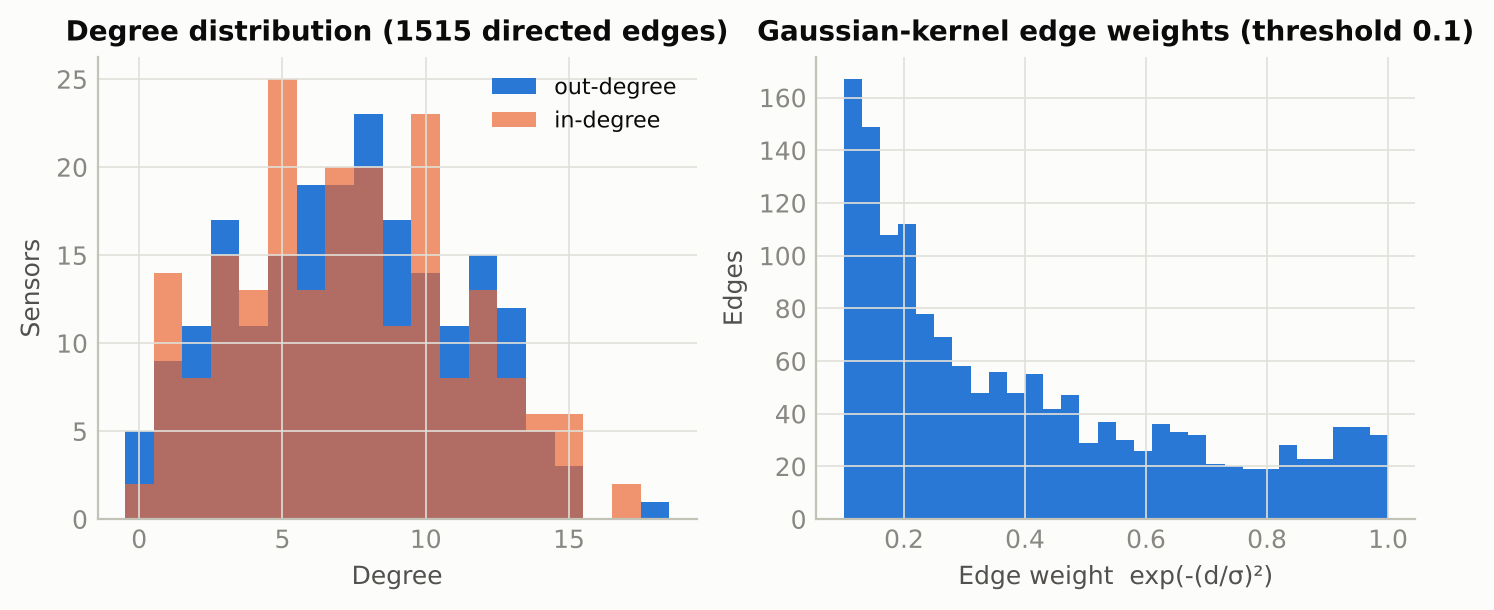

In [9]:
fig("fig_eda_sensor_map"); fig("fig_eda_spatial_correlation"); fig("fig_eda_graph")

In [10]:
pd.Series({k: summary[k] for k in ["corr_median_lt1km", "corr_median_5to6km", "corr_median_10to11km",
                                     "graph_edges", "graph_mean_out_degree", "graph_density", "graph_isolated_sensors"]}, name="value").to_frame()

,value
corr_median_lt1km,0.848
corr_median_5to6km,0.295
corr_median_10to11km,0.193
graph_edges,1515.000
graph_mean_out_degree,7.319
graph_density,0.035
graph_isolated_sensors,1.000


## 6. Per-sensor table and chronological split

In [11]:
sensor_tbl = pd.read_csv(C.RESULTS_DIR / "eda_sensor_table.csv")
sensor_tbl.describe().T[["mean", "min", "50%", "max"]]

,mean,min,50%,max
sensor_id,745460.203,7.163e+05,762329.000,774204.000
latitude,34.137,3.404e+01,34.149,34.222
longitude,-118.320,-1.185e+02,-118.298,-118.183
train_mean_speed,58.615,3.087e+01,59.771,67.762
train_std_speed,10.108,2.033e+00,10.171,23.587
train_frac_congested,0.080,4.168e-05,0.056,0.709
frac_missing,0.081,6.268e-02,0.070,0.201
out_degree,7.319,0.000e+00,7.000,18.000
in_degree,7.319,0.000e+00,7.000,17.000


,split,n_samples,start,end
0,train,23967,2012-03-01 00:55:00,2012-05-23 06:05:00
1,val,3403,2012-05-23 08:10:00,2012-06-04 03:40:00
2,test,6831,2012-06-04 05:45:00,2012-06-27 22:55:00


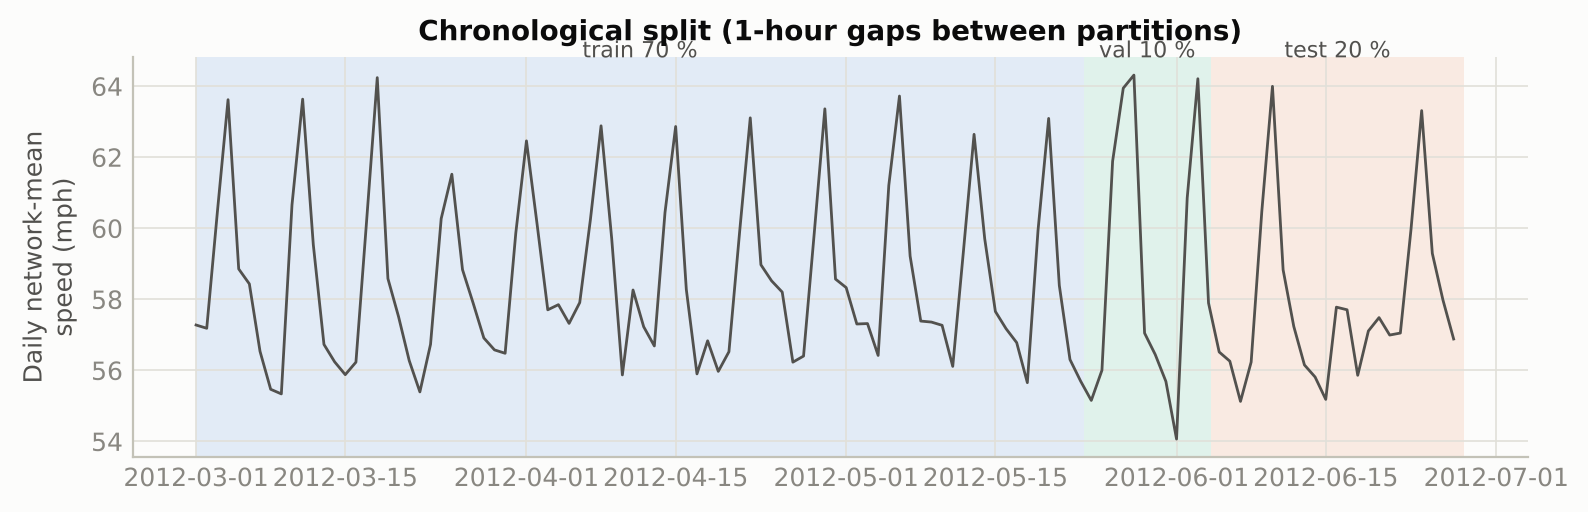

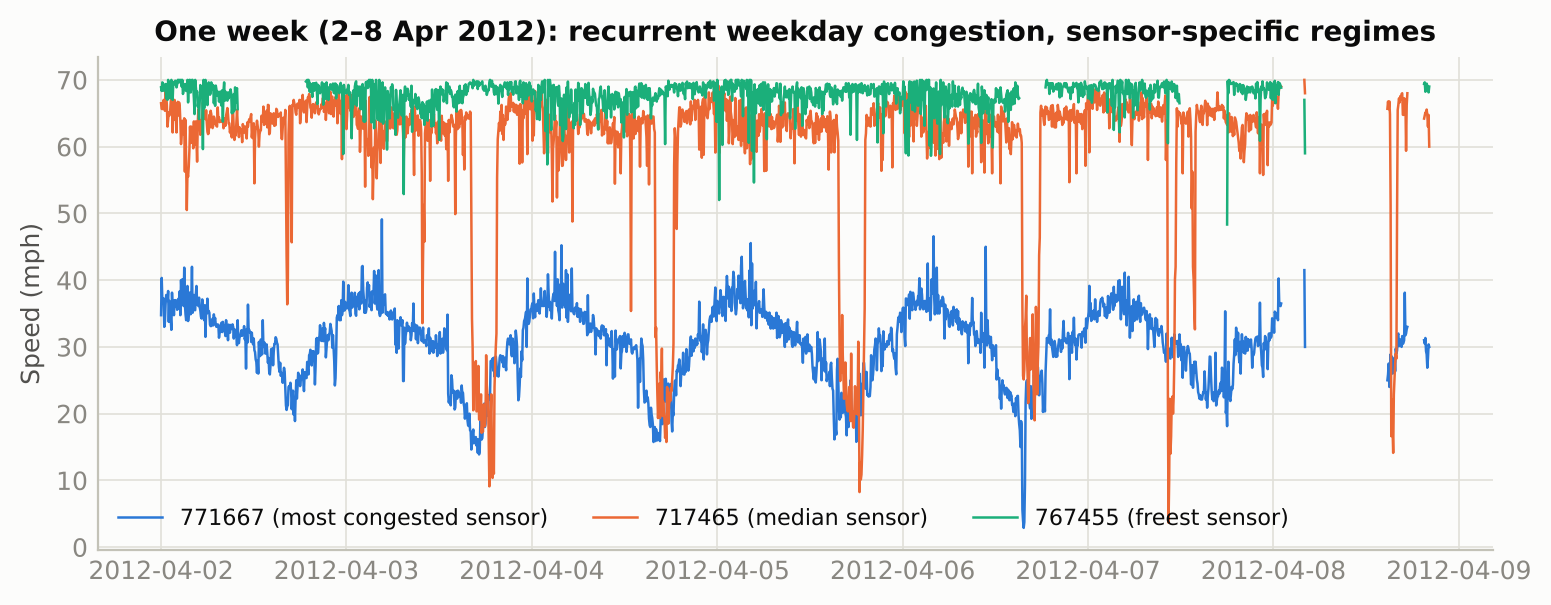

In [12]:
split = F.chronological_split(len(speed))
display(split.summary(speed.index))
fig("fig_eda_split_timeline"); fig("fig_eda_example_week")

## 7. Take-aways for modelling

1. **Mask outages** (NaN), never treat them as 0 mph; tree models handle NaN natively.
2. **Lag features** over the last hour capture the strong short-term memory; **cyclic calendar features** and a
   **train-only historical-average profile** capture the 24 h / weekly cycle.
3. **Neighbour features** from the road graph capture the local spatial dependence; the decay with distance says the
   first-hop neighbourhood is the right place to start.
4. **Chronological split** with a one-hour gap; evaluate separately in **peak** periods where congestion lives.